In [13]:
# Enable multiple outputs of a cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

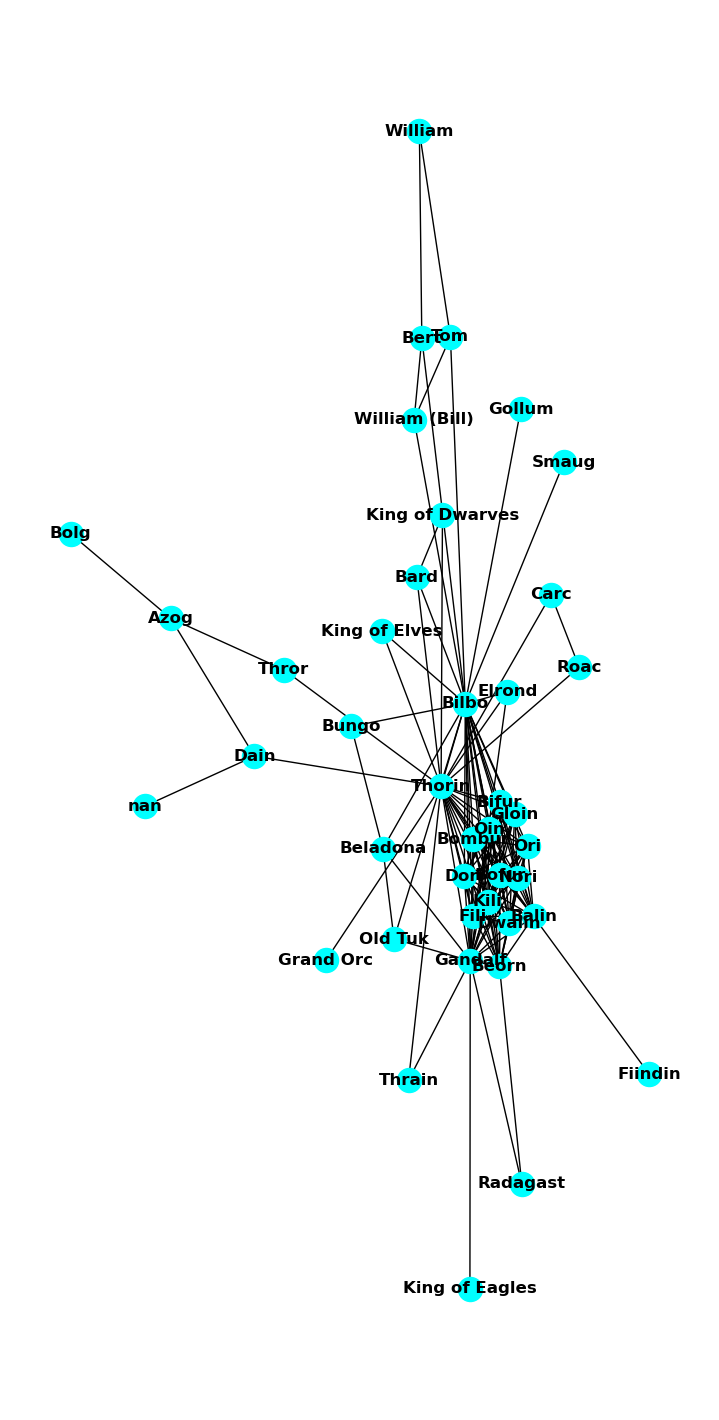

In [53]:
#import libraries
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy

# 1. LOAD THE RAW DATA
#We skip 42 row because it a name of character not a nodes or edges
df = pd.read_excel('data/Hobbit_Data.xlsx',sheet_name='Sheet1')
#Create empty network
G =nx.Graph()
#Add edges (the pair Source-Target in the dataframe)
G.add_edges_from([(row['Source'], row['Target']) for idx, row in df.iterrows()])
#Create a dict of name to map with the legend such as BI = Bilbo
name_map = {
    'AZ': 'Azog', 'BA': 'Balin', 'BD': 'Beladona', 'BE': 'Bert', 'BF': 'Bifur',
    'BI': 'Bilbo', 'BL': 'Bolg', 'BM': 'Bombur', 'BN': 'Beorn', 'BO': 'Bofur',
    'BR': 'Bard', 'BU': 'Bungo', 'CA': 'Carc', 'DA': 'Dain', 'DO': 'Dori',
    'DW': 'Dwalin', 'EL': 'Elrond', 'FI': 'Fili', 'FN': 'Fiindin', 'GA': 'Gandalf',
    'GC': 'Grand Orc', 'GL': 'Gloin', 'GO': 'Gollum', 'KA': 'King of Eagles',
    'KD': 'King of Dwarves', 'KE': 'King of Elves', 'KI': 'Kili', 'NA': 'Nain',
    'NO': 'Nori', 'OI': 'Oin', 'OR': 'Ori', 'OT': 'Old Tuk', 'RA': 'Radagast',
    'RO': 'Roac', 'SM': 'Smaug', 'TH': 'Thorin', 'TM': 'Tom', 'TO': 'Thror',
    'TR': 'Thrain', 'WB': 'William (Bill)', 'WI': 'William'
}
#Relebel the node to get full name.
G = nx.relabel_nodes(G, name_map)

#Draw the network
figure = plt.gcf()
pos = nx.spring_layout(G)#Position all node
nx.draw(G,pos, with_labels=True, node_color = 'cyan',font_weight='bold')
 #Tune different size of a figure and make it clear. 
figure.set_size_inches(7, 14)

In [39]:
#Compute the density
density_G=nx.density(G)
#print and compute number of node (numbers of characters) and number of edge (connections)
print("The number of nodes (characters) in G is: ", len(list(G.nodes)))
print("The number of edges (connections) in G is: ", len(list(G.edges)))
print("Network Density is",density_G)
#The network density is 0.195 (19.5%). This means that out of every possible character pairing in The Hobbit, only 19.5% of them actually met or interacted with each other in the story

The number of nodes (characters) in G is:  41
The number of edges (connections) in G is:  160
Network Density is 0.1951219512195122


In [41]:
#Compute the degree of node  G
degree_G=G.degree()
#We can see that Bilbo has degree value = 26 that mean he met 26 other chracter through out the story
print("The degrees of every node in G are ", degree_G)


The degrees of every node in G are  [('Azog', 3), ('Thror', 2), ('Balin', 16), ('Bifur', 15), ('Bilbo', 26), ('Bofur', 15), ('Bombur', 15), ('Dori', 15), ('Fili', 15), ('Gandalf', 21), ('Gloin', 13), ('Kili', 15), ('Nori', 15), ('Oin', 15), ('Ori', 14), ('Thorin', 25), ('Bard', 3), ('King of Dwarves', 2), ('Beladona', 4), ('Bungo', 2), ('Beorn', 15), ('Dwalin', 15), ('Bert', 4), ('Tom', 4), ('William', 2), ('Bolg', 1), ('Carc', 2), ('Roac', 2), ('Dain', 3), ('Elrond', 3), ('Fiindin', 1), ('Radagast', 2), ('Gollum', 1), ('Grand Orc', 1), (nan, 1), ('King of Elves', 2), ('King of Eagles', 1), ('Smaug', 1), ('Thrain', 2), ('Old Tuk', 3), ('William (Bill)', 3)]


In [42]:
#Compute mean degree of G
n1=len(list(G.nodes))#n1 is the number of nodes of G1
#########
#Compute the mean degrees of G
mean_degree_G = sum(dict(degree_G).values())/n1 
#Print out the mean degrees of G1 and G2
print("The mean degree of G is ", mean_degree_G)

#The network has a mean degree of 7.8, which mean that an average character in The Hobbit interacts with around 8 other individuals.
#So character that has degree more than 7.8 is a main character

The mean degree of G is  7.804878048780488


In [61]:
#Compute degree
degrees=dict(nx.degree(G))
print("The degrees of each node(characters):", degrees)

The degrees of each node(characters): {'Azog': 3, 'Thror': 2, 'Balin': 16, 'Bifur': 15, 'Bilbo': 26, 'Bofur': 15, 'Bombur': 15, 'Dori': 15, 'Fili': 15, 'Gandalf': 21, 'Gloin': 13, 'Kili': 15, 'Nori': 15, 'Oin': 15, 'Ori': 14, 'Thorin': 25, 'Bard': 3, 'King of Dwarves': 2, 'Beladona': 4, 'Bungo': 2, 'Beorn': 15, 'Dwalin': 15, 'Bert': 4, 'Tom': 4, 'William': 2, 'Bolg': 1, 'Carc': 2, 'Roac': 2, 'Dain': 3, 'Elrond': 3, 'Fiindin': 1, 'Radagast': 2, 'Gollum': 1, 'Grand Orc': 1, nan: 1, 'King of Elves': 2, 'King of Eagles': 1, 'Smaug': 1, 'Thrain': 2, 'Old Tuk': 3, 'William (Bill)': 3}


In [60]:
#compute degree centrality
centrality = nx.degree_centrality(G)
print("The degrees centrality of each node(characters) is:",degrees)

The degrees centrality of each node(characters) is: {'Azog': 3, 'Thror': 2, 'Balin': 16, 'Bifur': 15, 'Bilbo': 26, 'Bofur': 15, 'Bombur': 15, 'Dori': 15, 'Fili': 15, 'Gandalf': 21, 'Gloin': 13, 'Kili': 15, 'Nori': 15, 'Oin': 15, 'Ori': 14, 'Thorin': 25, 'Bard': 3, 'King of Dwarves': 2, 'Beladona': 4, 'Bungo': 2, 'Beorn': 15, 'Dwalin': 15, 'Bert': 4, 'Tom': 4, 'William': 2, 'Bolg': 1, 'Carc': 2, 'Roac': 2, 'Dain': 3, 'Elrond': 3, 'Fiindin': 1, 'Radagast': 2, 'Gollum': 1, 'Grand Orc': 1, nan: 1, 'King of Elves': 2, 'King of Eagles': 1, 'Smaug': 1, 'Thrain': 2, 'Old Tuk': 3, 'William (Bill)': 3}


In [62]:
#Compute closeness centrality
closeness=dict(nx.closeness_centrality(G))
print("The closeness centrality of each node:", closeness)


The closeness centrality of each node: {'Azog': 0.32, 'Thror': 0.43478260869565216, 'Balin': 0.5797101449275363, 'Bifur': 0.5714285714285714, 'Bilbo': 0.6896551724137931, 'Bofur': 0.5714285714285714, 'Bombur': 0.5714285714285714, 'Dori': 0.5714285714285714, 'Fili': 0.5714285714285714, 'Gandalf': 0.625, 'Gloin': 0.5555555555555556, 'Kili': 0.5714285714285714, 'Nori': 0.5714285714285714, 'Oin': 0.5714285714285714, 'Ori': 0.5633802816901409, 'Thorin': 0.7017543859649122, 'Bard': 0.47058823529411764, 'King of Dwarves': 0.42105263157894735, 'Beladona': 0.43956043956043955, 'Bungo': 0.4166666666666667, 'Beorn': 0.5714285714285714, 'Dwalin': 0.5714285714285714, 'Bert': 0.43010752688172044, 'Tom': 0.43010752688172044, 'William': 0.3053435114503817, 'Bolg': 0.24390243902439024, 'Carc': 0.42105263157894735, 'Roac': 0.42105263157894735, 'Dain': 0.4444444444444444, 'Elrond': 0.4819277108433735, 'Fiindin': 0.37037037037037035, 'Radagast': 0.39215686274509803, 'Gollum': 0.41237113402061853, 'Grand O

In [63]:
#Compute betweeness centrality
betweenness=dict(nx.betweenness_centrality(G))
print("The betweenness centrality of each node:", betweenness)

The betweenness centrality of each node: {'Azog': 0.05128205128205128, 'Thror': 0.046153846153846156, 'Balin': 0.05019723865877712, 'Bifur': 0.00019723865877712034, 'Bilbo': 0.3788297172912557, 'Bofur': 0.00019723865877712034, 'Bombur': 0.00019723865877712034, 'Dori': 0.00019723865877712034, 'Fili': 0.00019723865877712034, 'Gandalf': 0.13246219592373437, 'Gloin': 0.0, 'Kili': 0.00019723865877712034, 'Nori': 0.00019723865877712034, 'Oin': 0.00019723865877712034, 'Ori': 0.0, 'Thorin': 0.4307527942143326, 'Bard': 0.005982905982905983, 'King of Dwarves': 0.0, 'Beladona': 0.0027777777777777783, 'Bungo': 0.0, 'Beorn': 0.0202991452991453, 'Dwalin': 0.00019723865877712034, 'Bert': 0.02435897435897436, 'Tom': 0.02435897435897436, 'William': 0.0, 'Bolg': 0.0, 'Carc': 0.0, 'Roac': 0.0, 'Dain': 0.09615384615384616, 'Elrond': 0.0, 'Fiindin': 0.0, 'Radagast': 0.0, 'Gollum': 0.0, 'Grand Orc': 0.0, nan: 0.02564102564102564, 'King of Elves': 0.0, 'King of Eagles': 0.0, 'Smaug': 0.0, 'Thrain': 0.0, 'Old

In [66]:
#find out the nodes with maximum values of the degree, closeness, and betweenness
max_degree=max(degrees.values())
max_closeness=max(closeness.values())
max_betweenness=max(betweenness.values())

max_degree_key=[items for items, value in degrees.items() 
                if value == max(degrees.values())]
max_closeness_key=[items for items, value in closeness.items() 
                if value == max(closeness.values())]
max_betweenness_key=[items for items, value in betweenness.items() 
                if value == max(betweenness.values())]

print("The nodes (character) with maximum degrees is ", max_degree_key, 
      ". The maximum degree is", max_degree)
print("The nodes (character)  with maximum closeness centrality is ", max_closeness_key, 
      ". The maximum closeness centrality is", max_closeness)
print("The nodes (character)  with maximum betweenness centrality is ", max_betweenness_key, 
      ". The maximum betweenness centrality is", max_betweenness)

The nodes (character) with maximum degrees is  ['Bilbo'] . The maximum degree is 26
The nodes (character)  with maximum closeness centrality is  ['Thorin'] . The maximum closeness centrality is 0.7017543859649122
The nodes (character)  with maximum betweenness centrality is  ['Thorin'] . The maximum betweenness centrality is 0.4307527942143326


Betweeness Centrality: tell us which node are the"bridges" or "connectors" within the network. It measures how often a specific node lies on the shortest path between any two other nodes that are trying to reach each other our result shows Thorin has the highest Betweenness Centrality at 0.431. that mean he is for nearly 43% of all character-to-character pairs in the story, Thorin is the "middle-man" they must go through to be connected.